# 学会预测动作后果，再规划 / A learned world model

小车位于位置 2.5，速度为 0。持续向左施力可以接近原点，到了原点仍向左施力却会冲过去。
我们先用随机动作收集轨迹，学习“当前状态和力矩如何决定下一步”，再比较候选动作序列。

CPU 默认 180 条随机轨迹、每条 30 步，900 次模型更新；规划每次搜索 256 条长度为 15 的序列。
无外部数据。动力学和奖励对应书中 `minimal_mbrl_point_mass.py`，这里增加轨迹级留出与漂移检查。


In [1]:
import importlib.util
import subprocess
import sys

packages = {"torch": "torch>=2.5,<3", "numpy": "numpy>=1.26,<3",
            "matplotlib": "matplotlib>=3.8,<4"}
missing = [spec for name, spec in packages.items() if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

torch.set_num_threads(1)
torch.manual_seed(7)
OUTPUT = Path(os.getenv("HANDS_ON_LAB_OUTPUT", "lab-output")) / "worldmodel"
OUTPUT.mkdir(parents=True, exist_ok=True)
UPDATES, HORIZON, CANDIDATES = 900, 15, 256


def env_step(state, action):
    force = action[..., 0].clamp(-1, 1)
    position, velocity = state[..., 0], state[..., 1]
    next_velocity = 0.95 * velocity + 0.15 * torch.tanh(force)
    next_position = position + next_velocity
    nxt = torch.stack([next_position, next_velocity], -1)
    reward = -(next_position.square() + 0.1 * next_velocity.square() + 0.001 * force.square())
    return nxt, reward


episodes = []
for _ in range(180):
    state = torch.randn(2) * torch.tensor([2.0, 0.5])
    states, actions, targets = [], [], []
    for _ in range(30):
        action = torch.empty(1).uniform_(-1, 1)
        nxt, reward = env_step(state, action)
        states.append(state)
        actions.append(action)
        targets.append(torch.cat([nxt - state, reward[None]]))
        state = nxt
    episodes.append((torch.stack(states), torch.stack(actions), torch.stack(targets)))
train = [torch.cat([episode[i] for episode in episodes[:140]]) for i in range(3)]
test = [torch.cat([episode[i] for episode in episodes[140:]]) for i in range(3)]
print({"train_shapes": [list(x.shape) for x in train],
       "test_shapes": [list(x.shape) for x in test], "split": "whole trajectories"})
assert train[0].shape == (4200, 2) and test[0].shape == (1200, 2)


{'train_shapes': [[4200, 2], [4200, 1], [4200, 3]], 'test_shapes': [[1200, 2], [1200, 1], [1200, 3]], 'split': 'whole trajectories'}


## 1. 零变化基线与学习模型 / Dynamics learning

目标的前两列是位置和速度的变化量，第三列是奖励。
按整条轨迹划分训练和测试，防止相邻帧落入两侧造成过于乐观的误差。
模型只拟合训练侧，测试侧只记录预测误差。


In [2]:
class Dynamics(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3, 64), nn.Tanh(), nn.Linear(64, 64),
                                 nn.Tanh(), nn.Linear(64, 3))

    def forward(self, state, action):
        return self.net(torch.cat([state, action], -1))


model = Dynamics()
optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
logs = []
for update in range(UPDATES):
    index = torch.randint(len(train[0]), (256,))
    pred = model(train[0][index], train[1][index])
    loss = (pred - train[2][index]).square().mean()
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if update % 30 == 0:
        with torch.no_grad():
            test_error = (model(test[0], test[1]) - test[2]).square().mean(0)
        logs.append([update, float(loss.detach()), *test_error.tolist()])
with torch.no_grad():
    one_step_mse = (model(test[0], test[1])[:, :2] - test[2][:, :2]).square().mean().item()
zero_delta_mse = test[2][:, :2].square().mean().item()
print({"zero_delta_state_mse": zero_delta_mse, "learned_state_mse": one_step_mse})
assert one_step_mse < zero_delta_mse


{'zero_delta_state_mse': 0.0724581927061081, 'learned_state_mse': 0.032912276685237885}


## 2. 多步滚动中的误差累积 / Open-loop drift

我们固定测试轨迹上的真实动作，连续用预测状态作为下一步输入。
这一步没有重新接收真实位置，能直接看到误差如何累积。
下一节的规划每走一步就重新读取真实状态，因此与这里的开环预测不同。


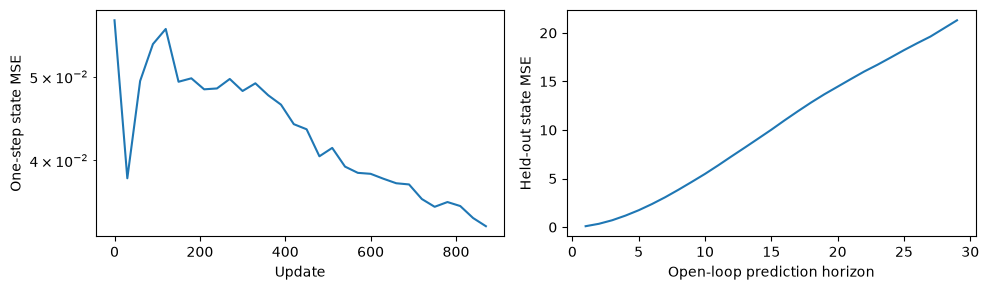

In [3]:
@torch.no_grad()
def drift(episode):
    states, actions, _ = episode
    imagined = states[0].clone()
    errors = []
    for step in range(len(actions) - 1):
        imagined = imagined + model(imagined, actions[step])[:2]
        errors.append(float((imagined - states[step + 1]).square().mean()))
    return errors


drift_errors = np.array([drift(episode) for episode in episodes[140:]])
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
logs = np.array(logs)
axes[0].semilogy(logs[:, 0], logs[:, 2:4].mean(-1), label="Held-out state MSE")
axes[0].set(xlabel="Update", ylabel="One-step state MSE")
axes[1].plot(np.arange(1, 30), drift_errors.mean(0))
axes[1].set(xlabel="Open-loop prediction horizon", ylabel="Held-out state MSE")
fig.tight_layout()
fig.savefig(OUTPUT / "model-errors.png", dpi=120)
plt.show()


## 3. 在模型内试动作，回真实环境执行一步 / Receding-horizon planning

规划器对每条候选序列累计预测奖励，只执行最高分序列的第一个动作，下一步重新搜索。
评估时，随机策略、零力矩和模型规划使用同一组初始状态，回报都由真实动力学计算。
规划利用模型误差也可能失败，因此同时报告每个初始状态的结果。


Random true returns: [-804.9, -2626.5, -118.5, -2516.4, -80.6, -142.8]
Zero torque true returns: [-250.0, -250.0, -1010.4, -1010.4, -330.0, -330.0]


Learned MPC true returns: [-29.0, -23.7, -19.2, -17.7, -5.8, -4.6]


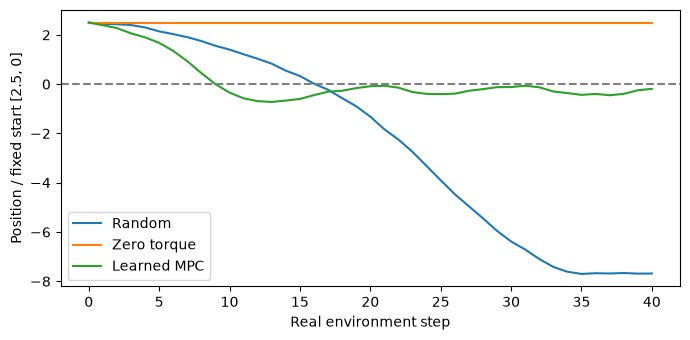

In [4]:
@torch.no_grad()
def plan(state):
    sequences = torch.empty(CANDIDATES, HORIZON, 1).uniform_(-1, 1)
    imagined = state[None].expand(CANDIDATES, -1).clone()
    scores = torch.zeros(CANDIDATES)
    for step in range(HORIZON):
        pred = model(imagined, sequences[:, step])
        imagined = imagined + pred[:, :2]
        scores += 0.97 ** step * pred[:, 2]
    return sequences[scores.argmax(), 0]


@torch.no_grad()
def rollout(policy, start):
    state, total, path = start.clone(), 0.0, [start.tolist()]
    for _ in range(40):
        state, reward = env_step(state, policy(state))
        total += reward.item()
        path.append(state.tolist())
    return total, path


starts = [torch.tensor([position, speed]) for position, speed in
          [(2.5, 0), (-2.5, 0), (1.5, 0.3), (-1.5, -0.3), (0.5, 0.2), (-0.5, -0.2)]]
results = {}
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, policy in [("Random", lambda s: torch.empty(1).uniform_(-1, 1)),
                     ("Zero torque", lambda s: torch.zeros(1)), ("Learned MPC", plan)]:
    samples = []
    for index, start in enumerate(starts):
        torch.manual_seed(1000 + index)
        samples.append(rollout(policy, start))
    results[name] = [sample[0] for sample in samples]
    ax.plot(np.array(samples[0][1])[:, 0], label=name)
    print(name, "true returns:", np.round(results[name], 1).tolist())
ax.axhline(0, color="grey", ls="--")
ax.set(xlabel="Real environment step", ylabel="Position / fixed start [2.5, 0]")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT / "planning.png", dpi=120)
plt.show()
assert np.isfinite([value for values in results.values() for value in values]).all()
metrics = {"test_state_mse": one_step_mse, "zero_delta_state_mse": zero_delta_mse,
           "open_loop_mse_at_29": float(drift_errors[:, -1].mean()), "true_returns": results}
(OUTPUT / "metrics.json").write_text(json.dumps(metrics, indent=2))
torch.save(model.state_dict(), OUTPUT / "dynamics.pt")


## 完成检查 / Checklist
- [ ] 训练测试按完整轨迹隔离，报告了独立的一步误差与多步漂移。
- [ ] 能区分预测下一状态的模型、比较未来的规划器和真实环境。
- [ ] 策略对照使用相同初始状态，收益从真实动力学获得。

## 练习 / Exercise
重新规划时填入实际执行的动作数。提示：每次搜索之后先执行一步，再读新状态。


In [5]:
RUN_EXERCISE = False
answer = None
if RUN_EXERCISE:
    assert answer == 1
else:
    print("Optional exercise: fill answer and enable RUN_EXERCISE.")


Optional exercise: fill answer and enable RUN_EXERCISE.


## 参考资料 / References
- [本书 Model-Based RL](https://walkinglabs.github.io/hands-on-modern-rl/chapter28_vla/embodied-intelligence/model-based-rl/)：
  对照学习动力学、模型误差与模型预测控制的不同作用。
- [PETS](https://arxiv.org/abs/1805.12114)：
  进一步阅读如何表示动力学的不确定性；本实验使用单个确定性小模型。


## 本次运行结果

CPU · Python 3.12.13 · 2.77 s

[查看完整结果页](https://walkinglabs.github.io/hands-on-modern-rl/lab-results/worldmodel-zh.html)
